# EAS over the nonadaptive 504-lattice — seed 1, data-seed1 receiver

**Population.** The 464 non-diverged seed-1 runs of the canonical nonadaptive 504-cell lattice
(9 lr x 7 alpha x 8 rank, ep20), distilled from the dog teacher
`dog/pythia-160m/ep2_lr5e-4_r32a64/ftseed1` onto the **cross-data-order receiver**
`pythia-160m-data-seed1` (the `orig -> ds1` arm). Each run carries a 41-point EAS trajectory:
40 checkpoints at steps 625, 1250, ..., 25000 plus an endpoint row that duplicates step 25000.

**Readout.** EAS = cosine between the student's extracted steering vector and the teacher's,
per residual-stream slot, in the `raw_blocks_v2` basis: slot 0 is the embedding and slot i is the
raw output of block i-1. `eas_mean` averages slots `[1:]` (12 raw block outputs, embedding
excluded). Every run's only reference is its own teacher, so `is_own_reference` is True everywhere.

**Label.** Collapsed / alive is the **unigram-anchored KL label** and nothing else: a run is
*collapsed* iff its endpoint excess-over-base Pile readout (`pile_probe.json`, pp1 pool) exceeds
the receiver's anchored cut `Delta_cross = H_uni - CE_base`. No trait / prior / `test_p` rule is
used for labelling anywhere in this notebook. Runs without a probe record are **unlabelled** and
are excluded from both classes -- never counted as alive.

## 0. Load + coverage

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import labels, probe_cache
from subliminal_learning.analysis import trajectories as tj
from subliminal_learning.steering.eas_results_io import endpoint_only, load_eas_results

REPO, OUT = bootstrap()
set_plot_style()

LINEAGE = ("students/dog/pythia-160m-data-seed1/teacher-pythia-160m/"
           "ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k")
RECEIVER = "pythia-160m-data-seed1"

# Population: the harvest's seed-1, non-diverged cells. Divergence is the ONLY exclusion.
harvest = json.loads((OUT / "analysis/nonadaptive_8x7_harvest.json").read_text())
cells = [d for d in harvest if d["seed"] == 1 and not d["diverged"]]
RUNS = [f"{LINEAGE}/{d['tag']}/ftseed1" for d in cells]
print(f"harvest rows {len(harvest)} -> seed==1 & not diverged: {len(cells)} cells / {len(RUNS)} runs")

print(f"\ncollapse-law constants (printed, never hard-coded): "
      f"B_LAW={cl.B_LAW}  C_LAW={cl.C_LAW}  KSTAR_CALIBRATED={cl.KSTAR_CALIBRATED:.3e}")

harvest rows 1008 -> seed==1 & not diverged: 464 cells / 464 runs

collapse-law constants (printed, never hard-coded): B_LAW=0.659  C_LAW=-0.164  KSTAR_CALIBRATED=8.790e-04


In [2]:
# EAS frame: one row per (run, checkpoint point, reference teacher), position "last".
eas = load_eas_results(OUT, run_rel_paths=RUNS, positions=["last"])
print(f"EAS frame {eas.shape[0]} rows x {eas.shape[1]} cols, {eas.run_path.nunique()} runs")
print("points per run:", sorted(eas.groupby("run_path").size().unique()),
      "| steps:", len(sorted(eas.step.unique())), "distinct, "
      f"{min(eas.step)}..{max(eas.step)}")
print("conventions:", sorted(eas.eas_mean_convention.dropna().unique()),
      "| is_own_reference all True:", bool(eas.is_own_reference.all()),
      "| references:", sorted(eas.reference.dropna().unique()))
print("nonfinite points:", int(eas.nonfinite.sum()),
      "| missing eas_mean:", int(eas.eas_mean.isna().sum()))
missing = sorted(set(RUNS) - set(eas.run_path))
print(f"runs with NO EAS document: {len(missing)}")

EAS frame 19024 rows x 33 cols, 464 runs
points per run: [np.int64(41)] | steps: 40 distinct, 625..25000
conventions: ['raw_blocks_v2'] | is_own_reference all True: True | references: ['dog/pythia-160m/ep2_lr5e-4_r32a64/ftseed1']
nonfinite points: 0 | missing eas_mean: 0
runs with NO EAS document: 0


In [3]:
# Run-level frame: harvest HPs + dose coordinate + anchored-KL label. Row unit = one run.
runs = pd.DataFrame(cells).rename(columns={"tag": "student_param_tag"})
runs["run_path"] = [f"{LINEAGE}/{t}/ftseed1" for t in runs.student_param_tag]
runs["K"] = cl.K_of(runs.lr, runs.alpha, runs["rank"])
runs["Krel"] = runs.K / cl.KSTAR_CALIBRATED

pc = probe_cache.load_probe_cache(OUT, RUNS)          # pp1 pool, excess-over-base `kl`
runs = runs.merge(pc[["run_path", "kl", "delta_ce"]], on="run_path", how="left")
CUT = labels.anchored_cut(OUT, RECEIVER)
runs["dead"] = labels.label_dead_kl(runs, CUT, kl_col="kl")
runs["label"] = runs.dead.map({True: "collapsed", False: "alive (anchored KL label)"})

n_lab = int(runs.dead.notna().sum())
print(f"anchored dead cut for {RECEIVER} (pp1 pool): Delta_cross = {CUT:.4f} nats")
print(f"probe records found: {len(pc)} / {len(RUNS)} runs")
print(f"labelled {n_lab}  |  UNLABELLED (no probe record, excluded from both classes) "
      f"{len(runs) - n_lab}")
print(runs.label.value_counts(dropna=False).to_string())
print(f"\nKrel range {runs.Krel.min():.3f} .. {runs.Krel.max():.1f}; "
      f"lr {sorted(runs.lr.unique())}")
print(f"alpha {sorted(runs.alpha.unique())} | rank {sorted(runs['rank'].unique())}")

pile_probe cache: 464 rows of 79868 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)
anchored dead cut for pythia-160m-data-seed1 (pp1 pool): Delta_cross = 5.1234 nats
probe records found: 464 / 464 runs
labelled 464  |  UNLABELLED (no probe record, excluded from both classes) 0
label
alive (anchored KL label)    274
collapsed                    190

Krel range 0.006 .. 22.3; lr [np.float64(5e-06), np.float64(1e-05), np.float64(2e-05), np.float64(5e-05), np.float64(0.0001), np.float64(0.0002), np.float64(0.0005), np.float64(0.001), np.float64(0.002)]
alpha [np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128), np.int64(256)] | rank [np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128)]


In [4]:
# Attach the run-level fields to the EAS rows; split the duplicated endpoint out.
RUN_COLS = ["run_path", "student_param_tag", "lr", "rank", "alpha", "test_p",
            "dw_fro", "dw_spec", "K", "Krel", "kl", "dead", "label"]
eas = eas.drop(columns=[c for c in RUN_COLS if c in eas.columns and c != "run_path"])
eas = eas.merge(runs[RUN_COLS], on="run_path", how="left")

END = endpoint_only(eas).copy()                  # one row per run (step 25000, is_endpoint)
TRAJ = eas[~eas.is_endpoint.astype(bool)].copy() # 40 checkpoints per run, no duplicate
print(f"endpoint frame: {len(END)} rows (row unit = one run) | "
      f"trajectory frame: {len(TRAJ)} rows = {TRAJ.run_path.nunique()} runs x "
      f"{int(len(TRAJ) / TRAJ.run_path.nunique())} checkpoints")

LAB_ORDER = ["alive (anchored KL label)", "collapsed"]
LAB_COL = dict(zip(LAB_ORDER, ["tab:blue", "tab:red"]))
KBINS = [0, 0.1, 0.3, 1, 3, np.inf]
KBIN_LABELS = ["<0.1", "0.1-0.3", "0.3-1", "1-3", ">=3"]
for f in (runs, END, TRAJ):
    f["kbin"] = pd.cut(f.Krel, KBINS, labels=KBIN_LABELS, right=False)
print("\nruns per K/K* bin (row unit = one run):")
print(runs.kbin.value_counts().reindex(KBIN_LABELS).to_string())

endpoint frame: 464 rows (row unit = one run) | trajectory frame: 18560 rows = 464 runs x 40 checkpoints

runs per K/K* bin (row unit = one run):
kbin
<0.1       104
0.1-0.3     82
0.3-1       86
1-3         82
>=3        110


## 1. Endpoint block-mean EAS

Row unit throughout this section is **one run** (its endpoint = step 25000), so there is no
within-run clustering in any statistic below. Selection: all 464 runs for the scatters;
dead/alive splits use the labelled subset only.

Spearman(endpoint eas_mean, test_p) over 464 runs: rho = 0.700  (p = 1.85e-69)


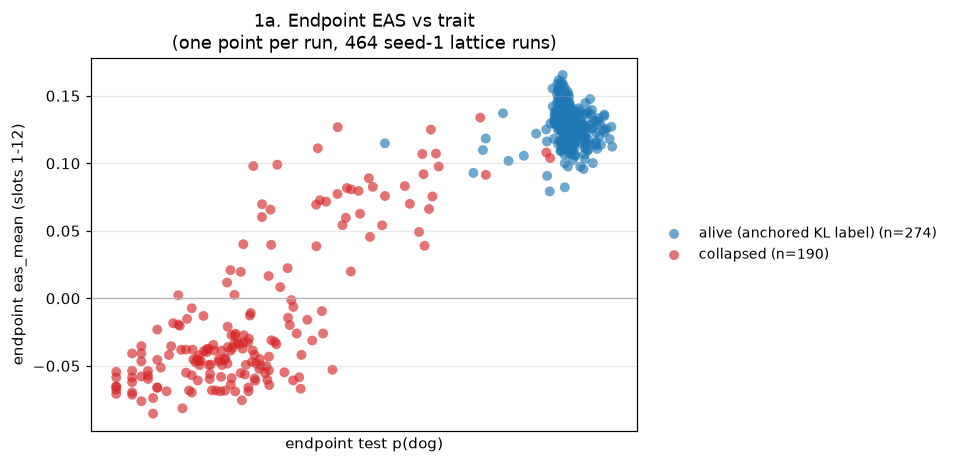

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for lab in LAB_ORDER:
    s = END[END.label == lab]
    ax.scatter(s.test_p, s.eas_mean, s=42, alpha=0.65, color=LAB_COL[lab],
               edgecolor="none", label=f"{lab} (n={len(s)})")
un = END[END.label.isna()]
if len(un):
    ax.scatter(un.test_p, un.eas_mean, s=42, alpha=0.65, color="0.6",
               marker="x", label=f"unlabelled (n={len(un)})")
ax.set_xscale("log"); aplots.plain_log_ticks(ax, axis="x")
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xlabel("endpoint test p(dog)"); ax.set_ylabel("endpoint eas_mean (slots 1-12)")
ax.set_title("1a. Endpoint EAS vs trait\n(one point per run, 464 seed-1 lattice runs)")
aplots.right_legend(ax)
r = spearmanr(END.test_p, END.eas_mean, nan_policy="omit")
print(f"Spearman(endpoint eas_mean, test_p) over {int(END[['test_p','eas_mean']].notna().all(1).sum())} "
      f"runs: rho = {r.statistic:.3f}  (p = {r.pvalue:.2e})")
plt.show()

Spearman(endpoint eas_mean, K/K*) over 464 runs: rho = -0.892 (p = 3.40e-161)


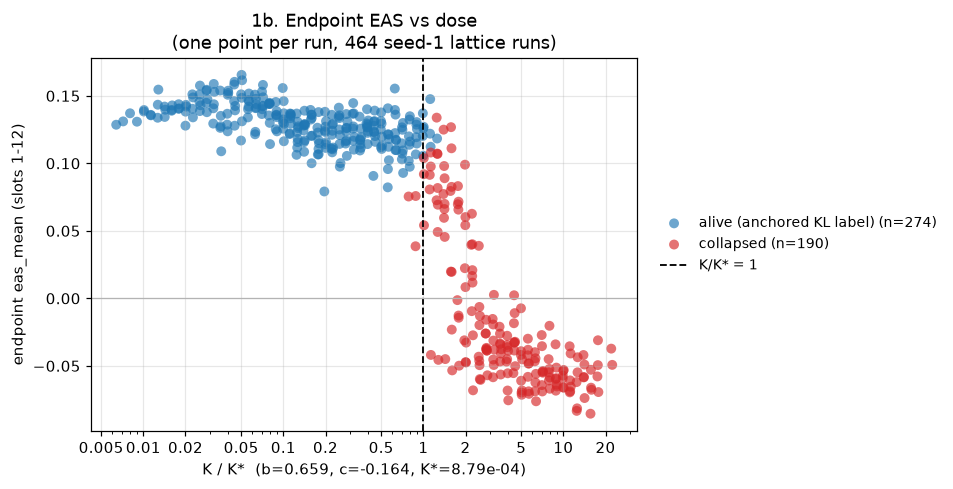

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for lab in LAB_ORDER:
    s = END[END.label == lab]
    ax.scatter(s.Krel, s.eas_mean, s=42, alpha=0.65, color=LAB_COL[lab],
               edgecolor="none", label=f"{lab} (n={len(s)})")
ax.axvline(1.0, color="k", ls="--", lw=1.2, label="K/K* = 1")
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xscale("log"); aplots.plain_log_ticks(ax, axis="x")
ax.set_xlabel(f"K / K*  (b={cl.B_LAW}, c={cl.C_LAW}, K*={cl.KSTAR_CALIBRATED:.2e})")
ax.set_ylabel("endpoint eas_mean (slots 1-12)")
ax.set_title("1b. Endpoint EAS vs dose\n(one point per run, 464 seed-1 lattice runs)")
aplots.right_legend(ax)
r = spearmanr(END.Krel, END.eas_mean, nan_policy="omit")
print(f"Spearman(endpoint eas_mean, K/K*) over {len(END)} runs: rho = {r.statistic:.3f} "
      f"(p = {r.pvalue:.2e})")
plt.show()

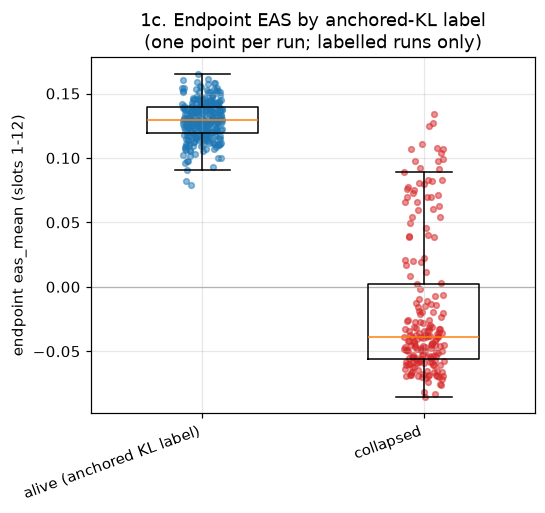

Row unit = one run (endpoint). Aggregation: distribution summary of eas_mean within label.
Selection: the 464 seed-1 non-diverged lattice runs that carry a probe record.



,n,mean,median,IQR_lo,IQR_hi,min,max
alive (anchored KL label),274,0.1292,0.1294,0.1194,0.1395,0.0792,0.1655
collapsed,190,-0.0175,-0.0387,-0.0558,0.0025,-0.0854,0.1339



alive-vs-collapsed AUC of endpoint eas_mean (score = eas_mean, positive = alive): 0.990


In [7]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
groups = [END[END.label == lab].eas_mean.to_numpy(float) for lab in LAB_ORDER]
aplots.strip_box(ax, groups, LAB_ORDER, colors=[LAB_COL[k] for k in LAB_ORDER], zero_line=True)
ax.set_ylabel("endpoint eas_mean (slots 1-12)")
ax.set_title("1c. Endpoint EAS by anchored-KL label\n(one point per run; labelled runs only)")
plt.show()

def _desc(v):
    v = pd.Series(v).dropna()
    return {"n": len(v), "mean": v.mean(), "median": v.median(),
            "IQR_lo": v.quantile(.25), "IQR_hi": v.quantile(.75),
            "min": v.min(), "max": v.max()}

tbl = pd.DataFrame([_desc(g) for g in groups], index=LAB_ORDER).round(4)
print("Row unit = one run (endpoint). Aggregation: distribution summary of eas_mean within label.")
print("Selection: the 464 seed-1 non-diverged lattice runs that carry a probe record.\n")
display(tbl)
lab = END.dropna(subset=["dead"])
print(f"\nalive-vs-collapsed AUC of endpoint eas_mean (score = eas_mean, positive = alive): "
      f"{roc_auc_score((~lab.dead.astype(bool)).astype(int), lab.eas_mean):.3f}")

## 2. Lattice view

Row unit = one run = one lattice cell (seed 1 only, so cell and run coincide). Each panel is
one learning rate; cells are rank x alpha. The value is the run's endpoint `eas_mean`
(diverging map centred at 0). Collapsed cells are boxed in the first panel set; the second
set shows the anchored-KL label itself (1 = collapsed).

boxed cells = 190 collapsed runs; colour scale +/-0.17


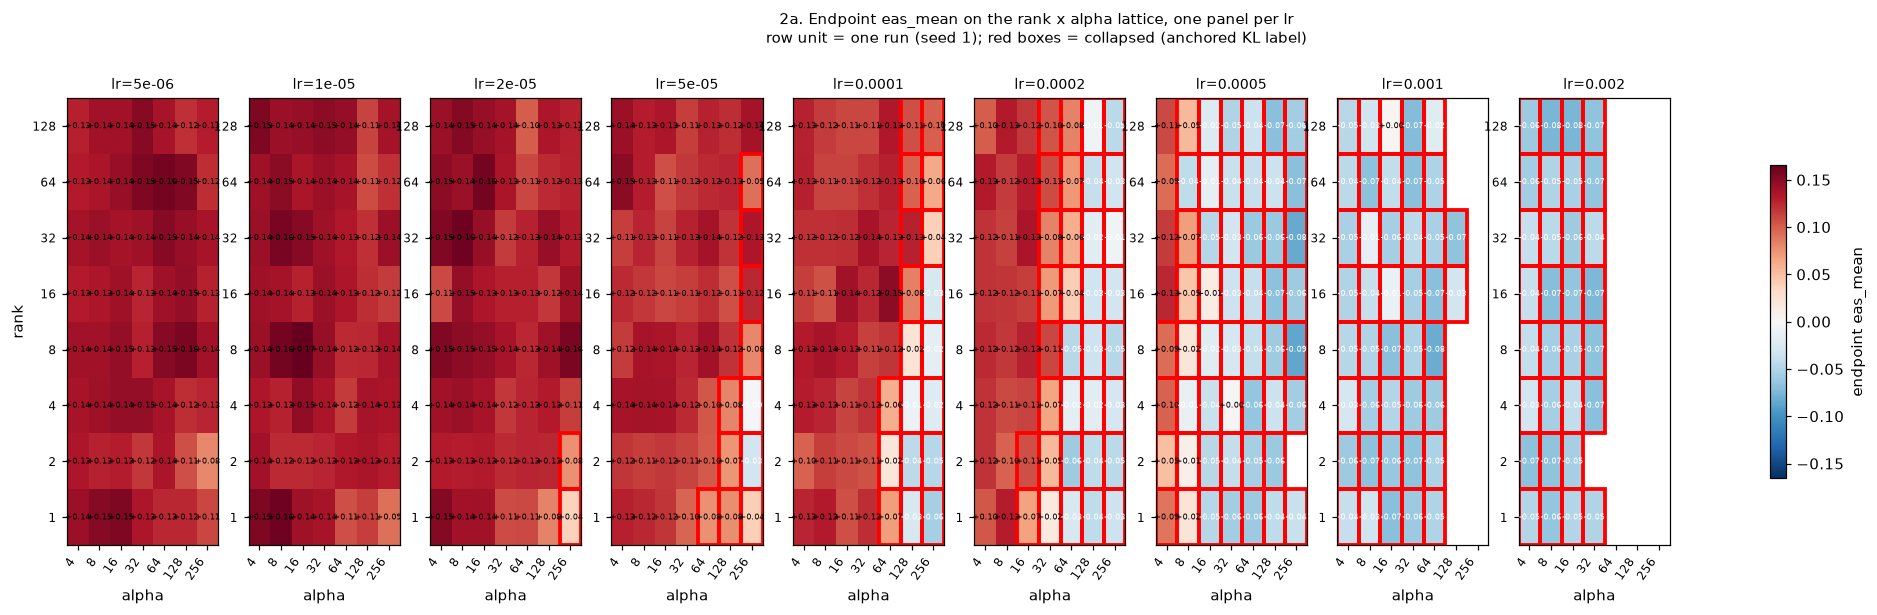

In [8]:
grid_df = END.copy()
hl = [{"lr": r.lr, "rank": r["rank"], "alpha": r.alpha}
      for _, r in grid_df[grid_df.dead == True].iterrows()]  # noqa: E712
vmax = float(np.nanmax(np.abs(grid_df.eas_mean)))
fig = aplots.facet_grid_heatmaps(
    grid_df, row="rank", col="alpha", val="eas_mean", col_facet="lr",
    cmap="RdBu_r", vmin=-vmax, vmax=vmax, mid=0.0, fmt="{:+.2f}",
    highlight=hl, panel_w=2.5, row_h=0.36, cell_fontsize=5.5,
    cbar_label="endpoint eas_mean",
    col_facet_label=lambda v: f"lr={v:g}",
    title=("2a. Endpoint eas_mean on the rank x alpha lattice, one panel per lr\n"
           "row unit = one run (seed 1); red boxes = collapsed (anchored KL label)"))
print(f"boxed cells = {len(hl)} collapsed runs; colour scale +/-{vmax:.2f}")
plt.show()

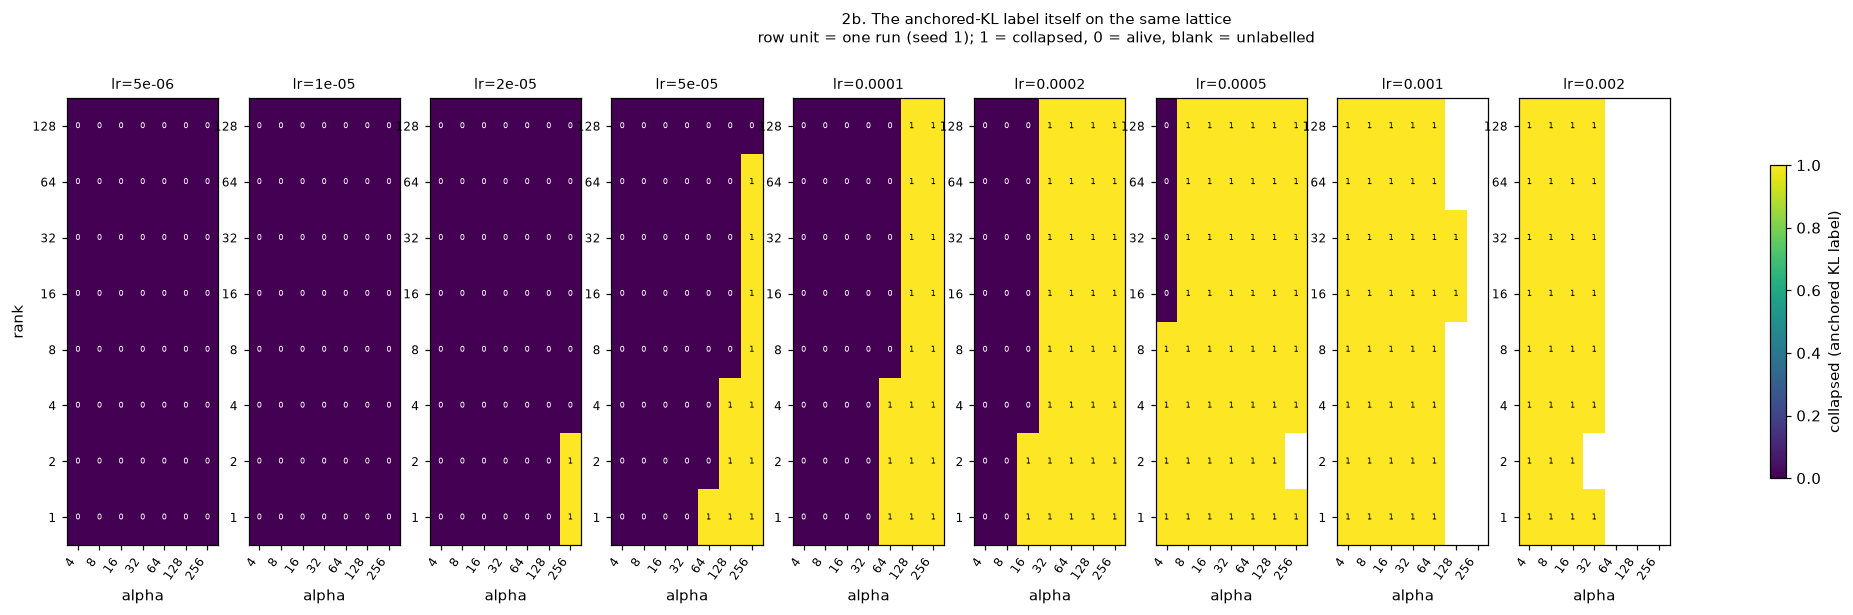

In [9]:
grid_df["dead_num"] = grid_df.dead.map({True: 1.0, False: 0.0})
fig = aplots.facet_grid_heatmaps(
    grid_df, row="rank", col="alpha", val="dead_num", col_facet="lr",
    cmap="viridis", vmin=0.0, vmax=1.0, fmt="{:.0f}",
    panel_w=2.5, row_h=0.36, cell_fontsize=5.5,
    cbar_label="collapsed (anchored KL label)",
    col_facet_label=lambda v: f"lr={v:g}",
    title=("2b. The anchored-KL label itself on the same lattice\n"
           "row unit = one run (seed 1); 1 = collapsed, 0 = alive, blank = unlabelled"))
plt.show()

## 3. Individual layers

`eas_per_layer` has 13 slots: slot 0 is the embedding (excluded from every block statistic
below) and slot i is the raw output of block i-1. Slots 1-12 are the 12 transformer blocks,
slot 12 being the last block.

In [10]:
SLOTS = np.arange(13)
BLOCK = SLOTS[1:]                      # slots 1..12 = the 12 raw block outputs

def slot_matrix(frame, col):
    """(n_rows, 13) float array of a per-layer list column; short/missing rows -> NaN."""
    out = np.full((len(frame), 13), np.nan)
    for i, v in enumerate(frame[col].to_numpy()):
        if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 13:
            out[i] = np.asarray(v, dtype=float)
    return out

PL_T = slot_matrix(TRAJ, "eas_per_layer")     # trajectory rows (40/run)
PL_E = slot_matrix(END, "eas_per_layer")      # endpoint rows (1/run)
print(f"per-layer matrices: trajectory {PL_T.shape}, endpoint {PL_E.shape}; "
      f"rows with a full 13-slot list: {int(np.isfinite(PL_T).all(1).sum())} / {len(PL_T)} "
      f"and {int(np.isfinite(PL_E).all(1).sum())} / {len(PL_E)}")

per-layer matrices: trajectory (18560, 13), endpoint (464, 13); rows with a full 13-slot list: 18560 / 18560 and 464 / 464


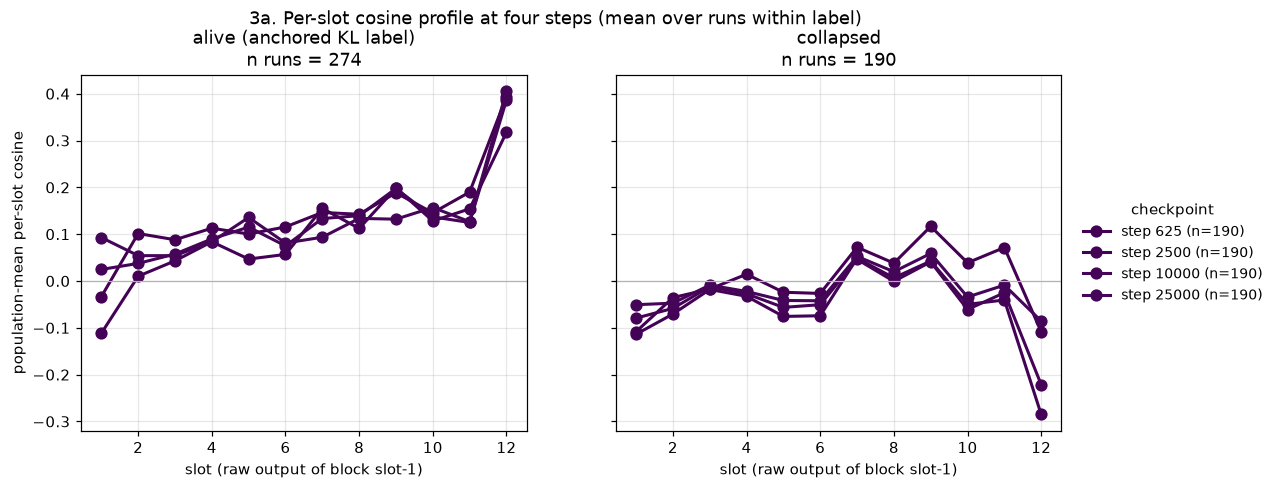

In [11]:
PROFILE_STEPS = [625, 2500, 10000, 25000]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
cols = aplots.palette(PROFILE_STEPS, "viridis")
for ax, lab in zip(axes, LAB_ORDER):
    m = (TRAJ.label == lab).to_numpy()
    for st in PROFILE_STEPS:
        sel = m & (TRAJ.step == st).to_numpy()
        prof = np.nanmean(PL_T[sel][:, BLOCK], axis=0)
        ax.plot(BLOCK, prof, marker="o", ms=7, lw=2, color=cols[st],
                label=f"step {st} (n={int(sel.sum())})")
    ax.axhline(0, color="0.7", lw=0.8)
    ax.set_xlabel("slot (raw output of block slot-1)")
    ax.set_title(f"{lab}\nn runs = {int((runs.label == lab).sum())}")
axes[0].set_ylabel("population-mean per-slot cosine")
aplots.right_legend(axes[1], title="checkpoint")
fig.suptitle("3a. Per-slot cosine profile at four steps (mean over runs within label)", y=1.02)
plt.show()

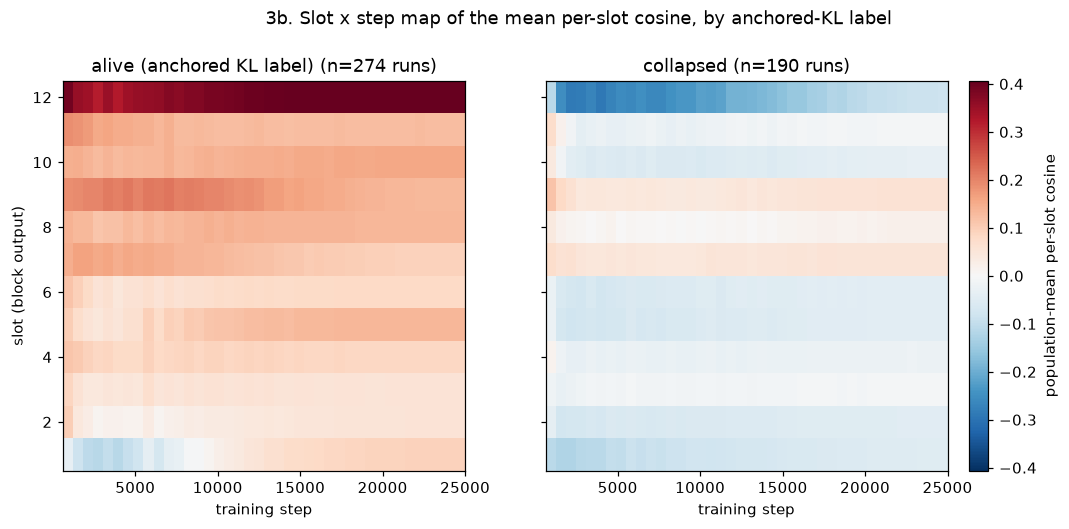

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
steps = sorted(TRAJ.step.unique())
ims = []
for ax, lab in zip(axes, LAB_ORDER):
    m = (TRAJ.label == lab).to_numpy()
    grid = np.vstack([np.nanmean(PL_T[m & (TRAJ.step == st).to_numpy()][:, BLOCK], axis=0)
                      for st in steps]).T                       # slots x steps
    ims.append((ax, grid))
vmax = max(np.nanmax(np.abs(g)) for _, g in ims)
for (ax, grid), lab in zip(ims, LAB_ORDER):
    im = ax.imshow(grid, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                   extent=[steps[0], steps[-1], BLOCK[0] - .5, BLOCK[-1] + .5])
    ax.set_xlabel("training step"); ax.grid(False)
    ax.set_title(f"{lab} (n={int((runs.label == lab).sum())} runs)")
axes[0].set_ylabel("slot (block output)")
fig.colorbar(im, ax=axes, label="population-mean per-slot cosine", pad=0.02)
fig.suptitle("3b. Slot x step map of the mean per-slot cosine, by anchored-KL label", y=1.02)
plt.show()

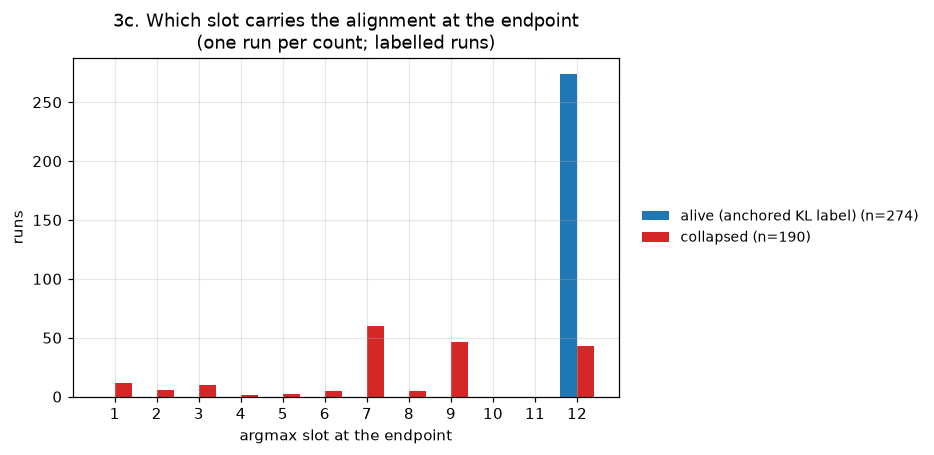

Row unit = one run (endpoint). Aggregation: count of runs whose max per-slot cosine (slots 1-12) sits at each slot.



label,alive (anchored KL label),collapsed
argmax_slot,,
1,0,12
2,0,6
3,0,10
4,0,1
5,0,2
6,0,5
7,0,60
8,0,5
9,0,46



overall modal argmax slot: 12 (317 / 464 runs)


In [13]:
arg = BLOCK[np.nanargmax(np.where(np.isfinite(PL_E[:, BLOCK]), PL_E[:, BLOCK], -np.inf), axis=1)]
END["argmax_slot"] = arg
fig, ax = plt.subplots(figsize=(6.4, 4.0))
w = 0.4
for i, lab in enumerate(LAB_ORDER):
    v = END[END.label == lab].argmax_slot
    cnt = v.value_counts().reindex(BLOCK, fill_value=0)
    ax.bar(BLOCK + (i - .5) * w, cnt.to_numpy(), width=w, color=LAB_COL[lab],
           label=f"{lab} (n={len(v)})")
ax.set_xticks(BLOCK); ax.set_xlabel("argmax slot at the endpoint"); ax.set_ylabel("runs")
ax.set_title("3c. Which slot carries the alignment at the endpoint\n(one run per count; labelled runs)")
aplots.right_legend(ax)
plt.show()
print("Row unit = one run (endpoint). Aggregation: count of runs whose max per-slot cosine "
      "(slots 1-12) sits at each slot.\n")
display(pd.crosstab(END.argmax_slot, END.label).reindex(BLOCK, fill_value=0))
print(f"\noverall modal argmax slot: {int(END.argmax_slot.mode().iloc[0])} "
      f"({int((END.argmax_slot == END.argmax_slot.mode().iloc[0]).sum())} / {len(END)} runs)")

In [14]:
END["eas_best_slot"] = np.nanmax(PL_E[:, BLOCK], axis=1)
END["eas_slot12"] = PL_E[:, 12]
READOUTS = {"block mean [1:]": "eas_mean", "best slot (max 1-12)": "eas_best_slot",
            "slot 12 (last block)": "eas_slot12"}
lab = END.dropna(subset=["dead"])
alive = (~lab.dead.astype(bool)).astype(int)
rows = []
for name, col in READOUTS.items():
    r = spearmanr(END.test_p, END[col], nan_policy="omit")
    rows.append({"readout": name,
                 "Spearman vs test_p": r.statistic, "p": r.pvalue,
                 "AUC alive vs collapsed": roc_auc_score(alive, lab[col]),
                 "median alive": lab[lab.dead == False][col].median(),   # noqa: E712
                 "median collapsed": lab[lab.dead == True][col].median()})  # noqa: E712
tbl3d = pd.DataFrame(rows).set_index("readout")
print("Row unit = one run (endpoint). Aggregation: one statistic per readout over all 464 runs")
print("(Spearman) / over the labelled runs (AUC, medians). Selection: seed-1 non-diverged lattice.")
print(f"AUC scores 'alive' as the positive class, so >0.5 means higher EAS goes with alive.\n")
display(tbl3d.round(4))

Row unit = one run (endpoint). Aggregation: one statistic per readout over all 464 runs
(Spearman) / over the labelled runs (AUC, medians). Selection: seed-1 non-diverged lattice.
AUC scores 'alive' as the positive class, so >0.5 means higher EAS goes with alive.



,Spearman vs test_p,p,AUC alive vs collapsed,median alive,median collapsed
readout,,,,,
block mean [1:],0.6997,0.0,0.9901,0.1294,-0.0387
best slot (max 1-12),0.6475,0.0,0.9944,0.4045,0.0699
slot 12 (last block),0.6313,0.0,0.9944,0.4045,-0.2117


## 4. Trajectories

x-axis is the **training step** (625, 1250, ..., 25000), never a fraction of training. The
duplicated endpoint row is dropped, so every run contributes exactly 40 points.

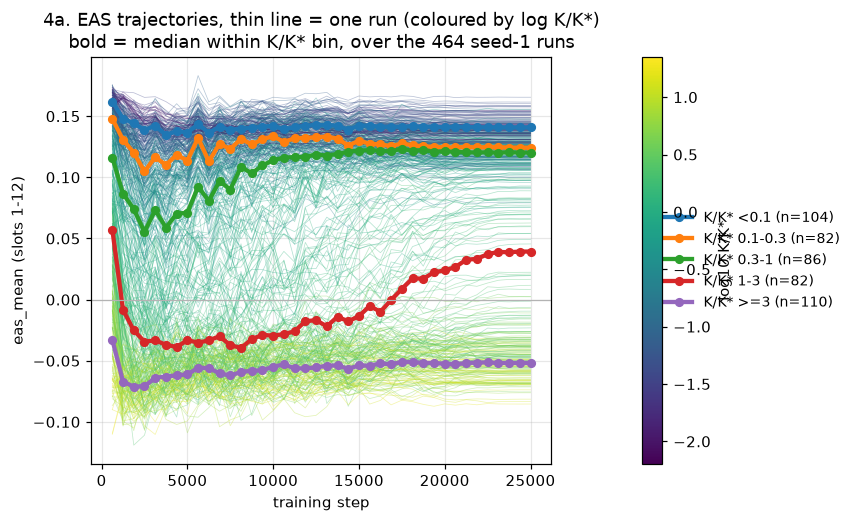

runs per K/K* bin (row unit = one run):
kbin
<0.1       104
0.1-0.3     82
0.3-1       86
1-3         82
>=3        110


In [15]:
norm = Normalize(vmin=np.log10(TRAJ.Krel.min()), vmax=np.log10(TRAJ.Krel.max()))
cmap = plt.get_cmap("viridis")
fig, ax = plt.subplots(figsize=(7.6, 4.8))
for rp, g in TRAJ.groupby("run_path"):
    g = g.sort_values("step")
    ax.plot(g.step, g.eas_mean, lw=0.5, alpha=0.35,
            color=cmap(norm(np.log10(g.Krel.iloc[0]))))
for kb in KBIN_LABELS:
    g = TRAJ[TRAJ.kbin == kb]
    if not len(g):
        continue
    med = g.groupby("step").eas_mean.median()
    ax.plot(med.index, med.to_numpy(), lw=2.8, marker="o", ms=5,
            label=f"K/K* {kb} (n={g.run_path.nunique()})")
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xlabel("training step"); ax.set_ylabel("eas_mean (slots 1-12)")
ax.set_title("4a. EAS trajectories, thin line = one run (coloured by log K/K*)\n"
             "bold = median within K/K* bin, over the 464 seed-1 runs")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="log10 K/K*", pad=0.14)
aplots.right_legend(ax, anchor=(1.22, 0.5))
plt.show()
print("runs per K/K* bin (row unit = one run):")
print(runs.kbin.value_counts().reindex(KBIN_LABELS).to_string())

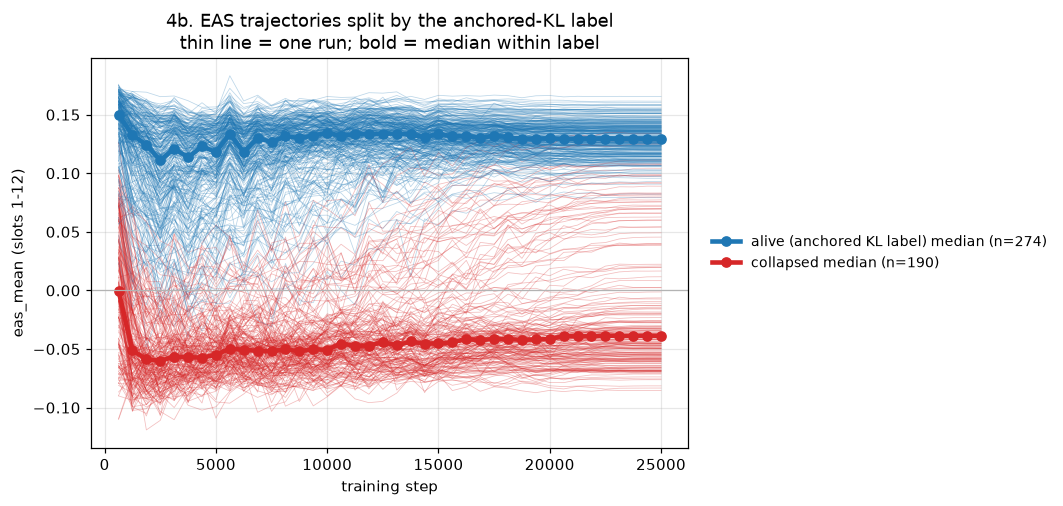

In [16]:
fig, ax = plt.subplots(figsize=(7.0, 4.6))
for rp, g in TRAJ.groupby("run_path"):
    g = g.sort_values("step")
    c = LAB_COL.get(g.label.iloc[0], "0.7")
    ax.plot(g.step, g.eas_mean, lw=0.5, alpha=0.3, color=c)
for lab in LAB_ORDER:
    g = TRAJ[TRAJ.label == lab]
    med = g.groupby("step").eas_mean.median()
    ax.plot(med.index, med.to_numpy(), lw=3, marker="o", ms=6, color=LAB_COL[lab],
            label=f"{lab} median (n={g.run_path.nunique()})")
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xlabel("training step"); ax.set_ylabel("eas_mean (slots 1-12)")
ax.set_title("4b. EAS trajectories split by the anchored-KL label\n"
             "thin line = one run; bold = median within label")
aplots.right_legend(ax)
plt.show()

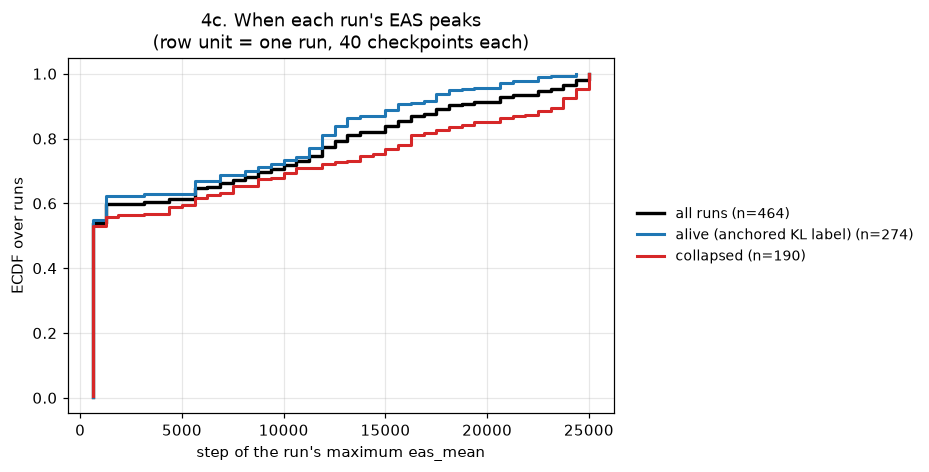

fraction of runs peaking at the FIRST checkpoint (step 625): 0.541 (251 / 464 runs)
median peak step 625; peak step <= 2500 for 0.599 of runs

fraction peaking at step 625 by label and by K/K* bin (row unit = one run):


,n,frac_peak@625,median_peak_step
label,,,
alive (anchored KL label),274,0.547,625.0
collapsed,190,0.532,625.0


,n,frac_peak@625,median_peak_step
kbin,,,
<0.1,104,0.702,625.0
0.1-0.3,82,0.659,625.0
0.3-1,86,0.291,11250.0
1-3,82,0.610,625.0
>=3,110,0.445,3750.0


In [17]:
pk = TRAJ.dropna(subset=["eas_mean"]).loc[
    TRAJ.dropna(subset=["eas_mean"]).groupby("run_path").eas_mean.idxmax(),
    ["run_path", "step", "eas_mean", "label", "kbin", "Krel"]
].rename(columns={"step": "peak_step", "eas_mean": "peak_eas"}).set_index("run_path")
END2 = END.set_index("run_path")
pk["end_eas"] = END2.eas_mean
fig, ax = plt.subplots(figsize=(6.4, 4.2))
aplots.ecdf_plot(ax, pk.peak_step, label=f"all runs (n={len(pk)})", lw=2.2, color="k")
for lab in LAB_ORDER:
    aplots.ecdf_plot(ax, pk[pk.label == lab].peak_step, lw=2,
                     color=LAB_COL[lab],
                     label=f"{lab} (n={int((pk.label == lab).sum())})")
ax.set_xlabel("step of the run's maximum eas_mean"); ax.set_ylabel("ECDF over runs")
ax.set_title("4c. When each run's EAS peaks\n(row unit = one run, 40 checkpoints each)")
aplots.right_legend(ax)
plt.show()
frac625 = float((pk.peak_step == 625).mean())
print(f"fraction of runs peaking at the FIRST checkpoint (step 625): {frac625:.3f} "
      f"({int((pk.peak_step == 625).sum())} / {len(pk)} runs)")
print(f"median peak step {pk.peak_step.median():.0f}; peak step <= 2500 for "
      f"{float((pk.peak_step <= 2500).mean()):.3f} of runs")
print("\nfraction peaking at step 625 by label and by K/K* bin (row unit = one run):")
display(pd.DataFrame({
    "n": pk.groupby("label", observed=True).size(),
    "frac_peak@625": pk.groupby("label", observed=True).peak_step.apply(lambda s: (s == 625).mean()),
    "median_peak_step": pk.groupby("label", observed=True).peak_step.median()}).round(3))
display(pd.DataFrame({
    "n": pk.groupby("kbin", observed=True).size(),
    "frac_peak@625": pk.groupby("kbin", observed=True).peak_step.apply(lambda s: (s == 625).mean()),
    "median_peak_step": pk.groupby("kbin", observed=True).peak_step.median()}).round(3))

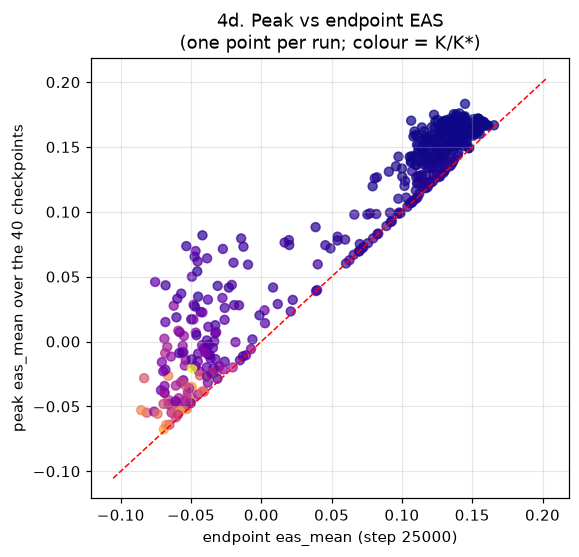

median peak 0.1346 vs median endpoint 0.1145; median peak-minus-endpoint drop 0.0216
runs whose endpoint is within 0.01 of the peak: 110 / 464


In [18]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
lim = (float(min(pk.end_eas.min(), pk.peak_eas.min())) - .02,
       float(max(pk.peak_eas.max(), pk.end_eas.max())) + .02)
aplots.identity_scatter(ax, pk.reset_index(), x="end_eas", y="peak_eas",
                        color_by="Krel", cmap="plasma", s=34, alpha=0.7,
                        stat="spearman", diag_lim=lim)
ax.set_xlabel("endpoint eas_mean (step 25000)"); ax.set_ylabel("peak eas_mean over the 40 checkpoints")
ax.set_title("4d. Peak vs endpoint EAS\n(one point per run; colour = K/K*)")
plt.show()
print(f"median peak {pk.peak_eas.median():.4f} vs median endpoint {pk.end_eas.median():.4f}; "
      f"median peak-minus-endpoint drop {float((pk.peak_eas - pk.end_eas).median()):.4f}")
print(f"runs whose endpoint is within 0.01 of the peak: "
      f"{int(((pk.peak_eas - pk.end_eas) < 0.01).sum())} / {len(pk)}")

In [19]:
FIXED = [625, 1250, 2500, 5000, 10000, 25000]
tbl4e = (TRAJ[TRAJ.step.isin(FIXED)].dropna(subset=["label"])
         .pivot_table(index="label", columns="step", values="eas_mean", aggfunc="median")
         .reindex(LAB_ORDER)[FIXED])
allmed = TRAJ[TRAJ.step.isin(FIXED)].groupby("step").eas_mean.median().reindex(FIXED)
tbl4e.loc["all runs (464)"] = allmed
print("Row unit = one run per (step, label) cell. Aggregation: MEDIAN eas_mean across runs.")
print("Selection: fixed checkpoint steps; label rows use the labelled runs only.\n")
display(tbl4e.round(4))

Row unit = one run per (step, label) cell. Aggregation: MEDIAN eas_mean across runs.
Selection: fixed checkpoint steps; label rows use the labelled runs only.



step,625,1250,2500,5000,10000,25000
label,,,,,,
alive (anchored KL label),0.1499,0.1326,0.1110,0.1181,0.1346,0.1294
collapsed,-0.0002,-0.0512,-0.0601,-0.0550,-0.0507,-0.0387
all runs (464),0.1139,0.0804,0.0521,0.0664,0.1029,0.1145


## 5. Is the decline lost alignment or dilution?

Resolve each slot's student vector into the component aligned with the teacher direction and
the component orthogonal to it:

`aligned = cos * |v_student|` and `orthogonal = |v_student| * sqrt(1 - cos^2)`.

If the cosine falls because the aligned part *shrinks*, the student is losing the teacher
direction; if the aligned part holds while the orthogonal part grows, the direction is being
**diluted** by unrelated drift.

student-norm rows complete: 18560 / 18560; teacher-norm rows complete: 18560 / 18560
teacher |v| per slot (constant, one reference teacher): [0.0, 0.418, 0.903, 1.705, 2.267, 3.231, 4.023, 5.358, 5.704, 6.332, 7.733, 10.887, 25.429]


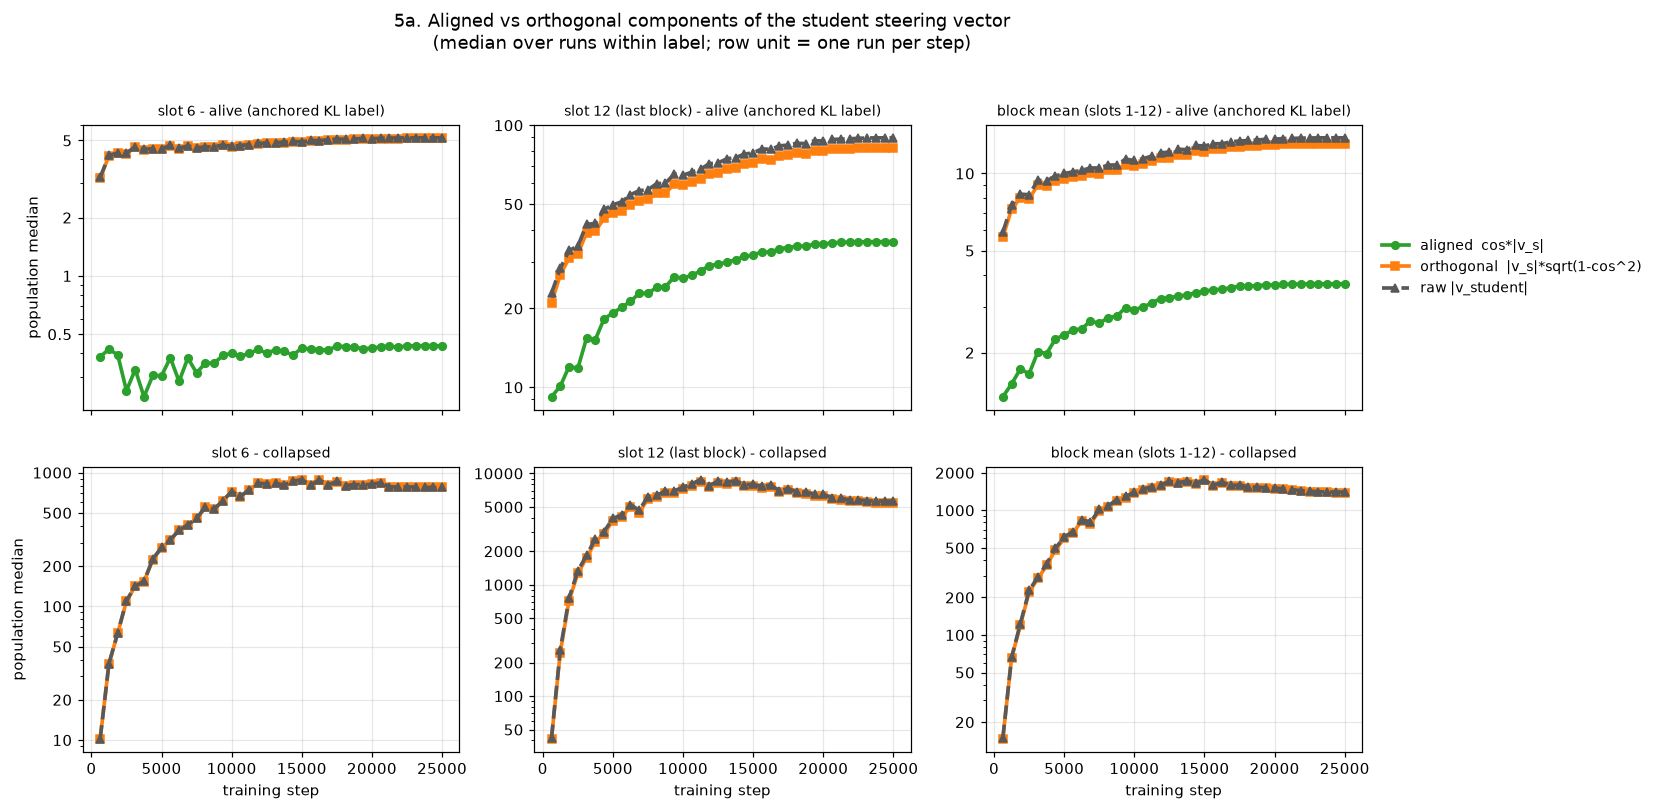

Row unit = one run per step; aggregation = population MEDIAN at steps 625 and 25000.
'ortho share' = orthogonal / |v_student| = sqrt(1-cos^2): the fraction of the student
vector that is NOT on the teacher direction. No aligned/ortho growth RATIO is quoted:
the collapsed aligned median starts near zero and changes sign, so a ratio is meaningless.
Selection: labelled runs.



aligned@625  aligned@25000  ortho@625  ortho@25000  |v_s|@625  |v_s|@25000  |v_s| growth x  ortho share@625  ortho share@25000
view                    label                                                                                                                                                    
slot 6                  alive (anchored KL label)       0.3827         0.4361     3.1895       5.1328     3.2243       5.1624          1.6011           0.9892             0.9943
                        collapsed                      -0.2001       -33.6266    10.2398     776.4073    10.2473     777.0944         75.8341           0.9993             0.9991
slot 12 (last block)    alive (anchored KL label)       9.2014        35.9603    21.0438      81.9647    22.8886      89.5834          3.9139           0.9194             0.9150
                        collapsed                      -7.3307     -1374.0864    41.4386    5459.4493    42.0624    5635.6606        133.9834           0.9852             0.9687
block mean (slots 1-12) alive (anchored KL label)       1.3445         3.7129     5.6444      13.0865     5.8995      13.7779          2.3355           0.9568             0.9498
                        collapsed                      -0.1679      -132.1342    14.7221    1386.9269    14.8552    1401.2381         94.3264           0.9910             0.9898

In [20]:
VS_T = slot_matrix(TRAJ, "v_student_norm_per_layer")
VT_T = slot_matrix(TRAJ, "v_teacher_norm_per_layer")
cos = np.clip(PL_T, -1.0, 1.0)
ALIGNED = cos * VS_T
ORTHO = VS_T * np.sqrt(np.clip(1.0 - cos ** 2, 0.0, None))
print(f"student-norm rows complete: {int(np.isfinite(VS_T).all(1).sum())} / {len(VS_T)}; "
      f"teacher-norm rows complete: {int(np.isfinite(VT_T).all(1).sum())} / {len(VT_T)}")
print("teacher |v| per slot (constant, one reference teacher):",
      np.round(np.nanmean(VT_T, axis=0), 3).tolist())

steps = sorted(TRAJ.step.unique())
step_arr = TRAJ.step.to_numpy()
def med_by_step(mat, mask):
    """Population MEDIAN of a per-row quantity at each step, within `mask`."""
    return np.array([np.nanmedian(mat[mask & (step_arr == st)]) for st in steps])

views = [("slot 6", lambda M: M[:, 6]), ("slot 12 (last block)", lambda M: M[:, 12]),
         ("block mean (slots 1-12)", lambda M: np.nanmean(M[:, BLOCK], axis=1))]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.4), sharex=True)
for j, (vname, pick) in enumerate(views):
    for i, lab in enumerate(LAB_ORDER):
        ax = axes[i][j]
        m = (TRAJ.label == lab).to_numpy()
        ax.plot(steps, med_by_step(pick(ALIGNED), m), lw=2.4, marker="o", ms=5,
                color="tab:green", label="aligned  cos*|v_s|")
        ax.plot(steps, med_by_step(pick(ORTHO), m), lw=2.4, marker="s", ms=5,
                color="tab:orange", label="orthogonal  |v_s|*sqrt(1-cos^2)")
        ax.plot(steps, med_by_step(pick(VS_T), m), lw=2.4, marker="^", ms=5,
                color="0.35", ls="--", label="raw |v_student|")
        ax.set_yscale("log"); aplots.plain_log_ticks(ax, axis="y")
        ax.set_title(f"{vname} - {lab}", fontsize=9)
        if i == 1:
            ax.set_xlabel("training step")
    axes[0][j].set_ylabel("") if j else None
axes[0][0].set_ylabel("population median")
axes[1][0].set_ylabel("population median")
aplots.right_legend(axes[0][2])
fig.suptitle("5a. Aligned vs orthogonal components of the student steering vector\n"
             "(median over runs within label; row unit = one run per step)", y=1.02)
plt.show()

summ5 = []
for vname, pick in views:
    for lab in LAB_ORDER:
        m = (TRAJ.label == lab).to_numpy()
        a, o, n = (med_by_step(pick(X), m) for X in (ALIGNED, ORTHO, VS_T))
        summ5.append({"view": vname, "label": lab,
                      "aligned@625": a[0], "aligned@25000": a[-1],
                      "ortho@625": o[0], "ortho@25000": o[-1],
                      "|v_s|@625": n[0], "|v_s|@25000": n[-1],
                      "|v_s| growth x": n[-1] / n[0],
                      "ortho share@625": o[0] / n[0], "ortho share@25000": o[-1] / n[-1]})
summ5 = pd.DataFrame(summ5).set_index(["view", "label"])
print("Row unit = one run per step; aggregation = population MEDIAN at steps 625 and 25000.")
print("'ortho share' = orthogonal / |v_student| = sqrt(1-cos^2): the fraction of the student")
print("vector that is NOT on the teacher direction. No aligned/ortho growth RATIO is quoted:")
print("the collapsed aligned median starts near zero and changes sign, so a ratio is meaningless.")
print("Selection: labelled runs.\n")
display(summ5.round(4))

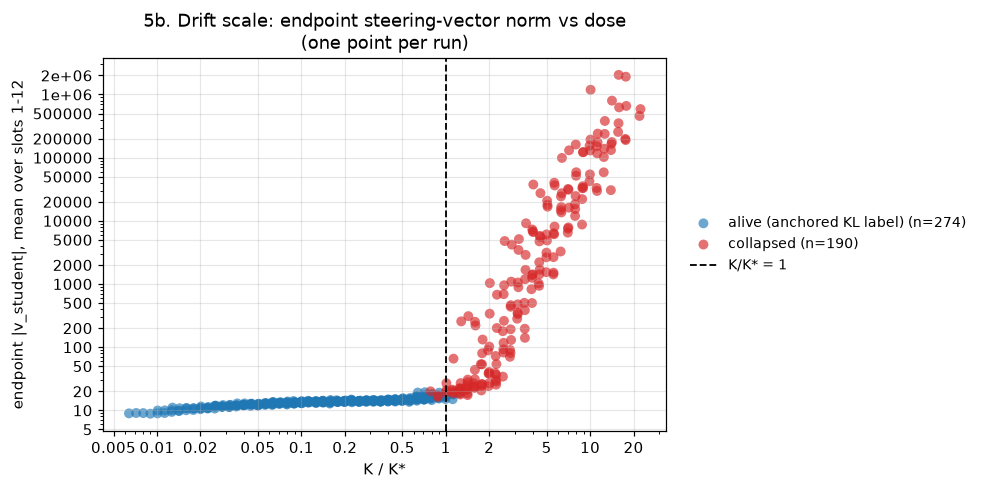

Spearman(endpoint |v_student| block mean, K/K*) over 464 runs: rho = 0.986 (p = 0.00e+00)
median endpoint |v_student| block mean: alive 13.778 vs collapsed 1401.238


In [21]:
END_VS = slot_matrix(END, "v_student_norm_per_layer")
END["vs_block_mean"] = np.nanmean(END_VS[:, BLOCK], axis=1)
fig, ax = plt.subplots(figsize=(6.6, 4.4))
for lab in LAB_ORDER:
    s = END[END.label == lab]
    ax.scatter(s.Krel, s.vs_block_mean, s=42, alpha=0.65, color=LAB_COL[lab],
               edgecolor="none", label=f"{lab} (n={len(s)})")
ax.axvline(1.0, color="k", ls="--", lw=1.2, label="K/K* = 1")
ax.set_xscale("log"); ax.set_yscale("log")
aplots.plain_log_ticks(ax)
ax.set_xlabel("K / K*"); ax.set_ylabel("endpoint |v_student|, mean over slots 1-12")
ax.set_title("5b. Drift scale: endpoint steering-vector norm vs dose\n(one point per run)")
aplots.right_legend(ax)
plt.show()
r = spearmanr(END.Krel, END.vs_block_mean, nan_policy="omit")
print(f"Spearman(endpoint |v_student| block mean, K/K*) over {len(END)} runs: "
      f"rho = {r.statistic:.3f} (p = {r.pvalue:.2e})")
print(f"median endpoint |v_student| block mean: alive "
      f"{END[END.dead == False].vs_block_mean.median():.3f} vs collapsed "  # noqa: E712
      f"{END[END.dead == True].vs_block_mean.median():.3f}")  # noqa: E712

## 6. EAS timing vs the trait and Pile-KL trajectories

Trait = mean exact p(dog) on the held-out **test** prompt set; Pile KL = `kl_base_adapted`
vs the run's own base. Both are read per checkpoint from the run-dir trajectory records
through the cached lineage loader (one batched sweep, not a per-run file walk).

In [22]:
registry = json.loads((REPO / "run_logs/strip_ckpt_replay_cells.json").read_text())
TAGS = set(runs.student_param_tag)
reg1 = dict(registry)
reg1["cells"] = {t: [1] for t, s in registry["cells"].items() if t in TAGS and 1 in s}
print(f"registry cells restricted to this population: {len(reg1['cells'])} / {len(TAGS)}")

LINEAGE_DIR = OUT / LINEAGE
pref = tj.load_lineage(reg1, LINEAGE_DIR, "pref", cache_root=OUT)
pkl = tj.load_lineage(reg1, LINEAGE_DIR, "pile_kl", cache_root=OUT)
print(f"coverage: pref (trait) trajectories {len(pref)} / {len(runs)} runs; "
      f"pile_kl trajectories {len(pkl)} / {len(runs)} runs")
print(f"runs with BOTH: {len(set(pref) & set(pkl))}; "
      f"runs with EAS and both: {len(set(pref) & set(pkl) & {(t, 1) for t in TAGS})}")

rows = []
for (tag, seed), t in pref.items():
    # a pref point's prompt set is {animal: {p_target, ...}}; series() resolves the animal,
    # so the remaining unwrap is the scorer field itself.
    for st, p in zip(t.steps, t.series("test", "dog")):
        rows.append({"student_param_tag": tag, "step": st,
                     "trait_p": p.get("p_target") if isinstance(p, dict) else p})
trait = pd.DataFrame(rows)
rows = []
for (tag, seed), t in pkl.items():
    for st, v in zip(t.steps, t.series("kl_base_adapted")):
        rows.append({"student_param_tag": tag, "step": st, "pile_kl": v})
kl_tr = pd.DataFrame(rows)
# Both record kinds repeat step 25000 (last checkpoint + endpoint); keep one row per (run, step)
# so the join to the 40-checkpoint EAS frame cannot duplicate rows.
for name, f in (("pref", trait), ("pile_kl", kl_tr)):
    print(f"{name}: {len(f)} points -> "
          f"{f.duplicated(['student_param_tag', 'step']).sum()} duplicate (run, step) rows dropped")
trait = trait.drop_duplicates(["student_param_tag", "step"])
kl_tr = kl_tr.drop_duplicates(["student_param_tag", "step"])
LONG = (TRAJ[["student_param_tag", "step", "eas_mean", "label", "kbin", "Krel"]]
        .merge(trait, on=["student_param_tag", "step"], how="left")
        .merge(kl_tr, on=["student_param_tag", "step"], how="left"))
LONG["pile_kl"] = pd.to_numeric(LONG.pile_kl, errors="coerce").replace(np.inf, np.nan)
print(f"\njoined long frame {LONG.shape}; missing trait points {int(LONG.trait_p.isna().sum())}, "
      f"missing/non-finite KL points {int(LONG.pile_kl.isna().sum())} "
      f"(of {len(LONG)} run-step rows)")

registry cells restricted to this population: 464 / 464


coverage: pref (trait) trajectories 464 / 464 runs; pile_kl trajectories 464 / 464 runs
runs with BOTH: 464; runs with EAS and both: 464
pref: 19024 points -> 464 duplicate (run, step) rows dropped
pile_kl: 19024 points -> 464 duplicate (run, step) rows dropped

joined long frame (18560, 8); missing trait points 0, missing/non-finite KL points 0 (of 18560 run-step rows)


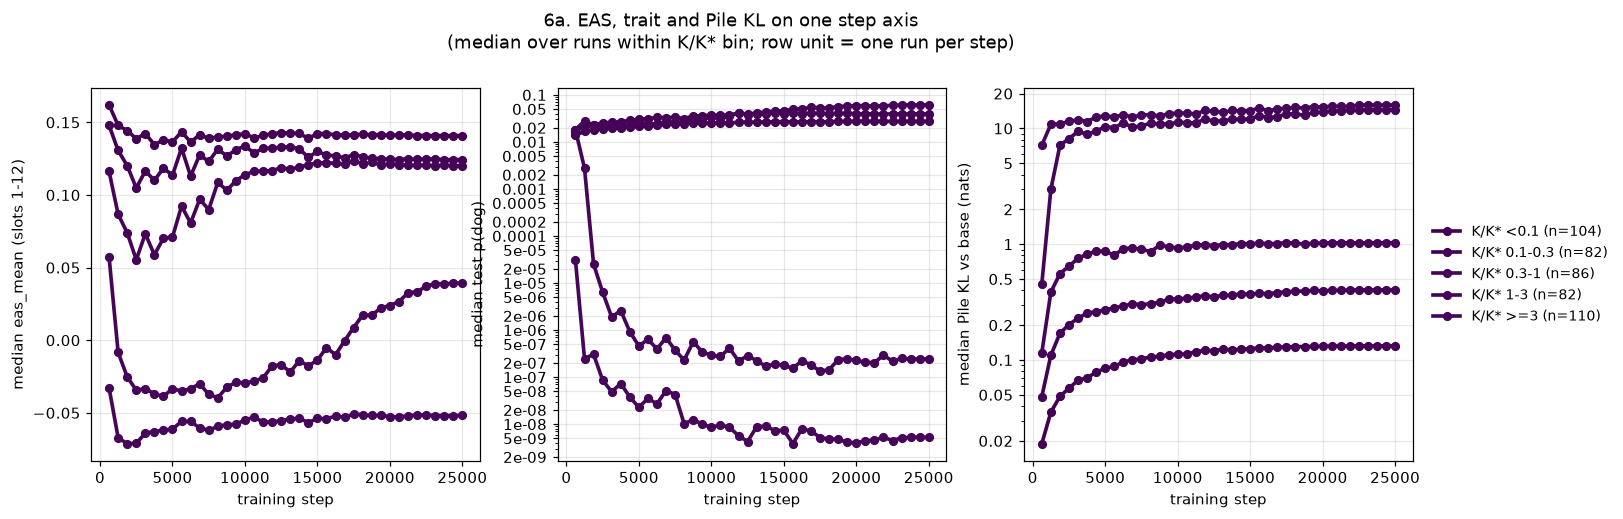

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
kcols = aplots.palette(KBIN_LABELS, "viridis")
panels = [("eas_mean", "median eas_mean (slots 1-12)", False),
          ("trait_p", "median test p(dog)", True),
          ("pile_kl", "median Pile KL vs base (nats)", True)]
for ax, (col, ylab, logy) in zip(axes, panels):
    for kb in KBIN_LABELS:
        g = LONG[LONG.kbin == kb]
        if not len(g):
            continue
        med = g.groupby("step")[col].median()
        ax.plot(med.index, med.to_numpy(), lw=2.4, marker="o", ms=5, color=kcols[kb],
                label=f"K/K* {kb} (n={g.student_param_tag.nunique()})")
    if logy:
        ax.set_yscale("log"); aplots.plain_log_ticks(ax, axis="y")
    ax.set_xlabel("training step"); ax.set_ylabel(ylab)
aplots.right_legend(axes[2])
fig.suptitle("6a. EAS, trait and Pile KL on one step axis\n"
             "(median over runs within K/K* bin; row unit = one run per step)", y=1.04)
plt.show()

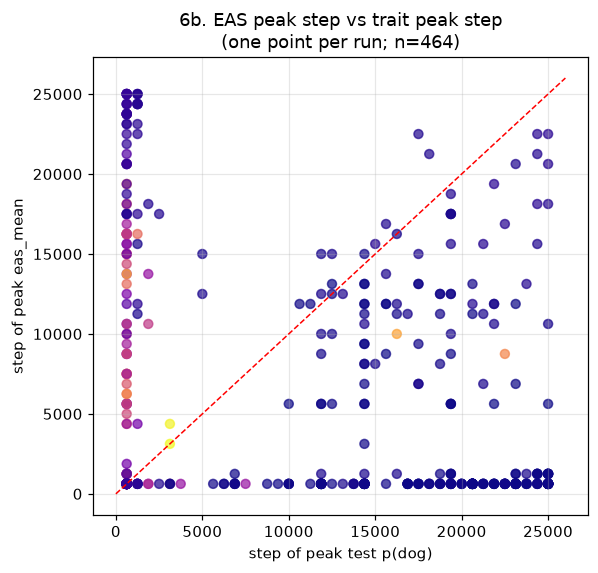

median EAS peak step 625 vs median trait peak step 11875
EAS peaks strictly EARLIER than the trait in 0.558 of runs; same step in 0.205


In [24]:
ep = LONG.dropna(subset=["eas_mean"]).loc[
    LONG.dropna(subset=["eas_mean"]).groupby("student_param_tag").eas_mean.idxmax(),
    ["student_param_tag", "step", "label", "Krel"]].rename(columns={"step": "eas_peak_step"})
tp = LONG.dropna(subset=["trait_p"]).loc[
    LONG.dropna(subset=["trait_p"]).groupby("student_param_tag").trait_p.idxmax(),
    ["student_param_tag", "step"]].rename(columns={"step": "trait_peak_step"})
peaks = ep.merge(tp, on="student_param_tag")
fig, ax = plt.subplots(figsize=(5.8, 5.4))
aplots.identity_scatter(ax, peaks, x="trait_peak_step", y="eas_peak_step",
                        color_by="Krel", cmap="plasma", s=34, alpha=0.7, stat="spearman",
                        diag_lim=(0, 26000))
ax.set_xlabel("step of peak test p(dog)"); ax.set_ylabel("step of peak eas_mean")
ax.set_title(f"6b. EAS peak step vs trait peak step\n(one point per run; n={len(peaks)})")
plt.show()
print(f"median EAS peak step {peaks.eas_peak_step.median():.0f} vs median trait peak step "
      f"{peaks.trait_peak_step.median():.0f}")
print(f"EAS peaks strictly EARLIER than the trait in "
      f"{float((peaks.eas_peak_step < peaks.trait_peak_step).mean()):.3f} of runs; "
      f"same step in {float((peaks.eas_peak_step == peaks.trait_peak_step).mean()):.3f}")

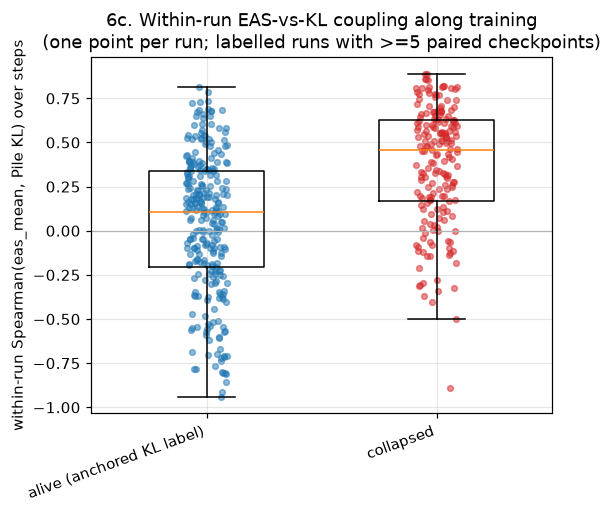

runs with a usable within-run correlation: 464 / 464
Row unit = one run. Aggregation: distribution of the within-run Spearman.



,n,median rho,IQR_lo,IQR_hi,frac rho<0
label,,,,,
alive (anchored KL label),274,0.107,-0.205,0.340,0.420
collapsed,190,0.456,0.170,0.627,0.153



all runs: median rho 0.208, frac negative 0.310


In [25]:
rho = []
for tag, g in LONG.groupby("student_param_tag"):
    g = g.dropna(subset=["eas_mean", "pile_kl"])
    if len(g) < 5 or g.pile_kl.nunique() < 3:
        continue
    r = spearmanr(g.eas_mean, g.pile_kl)
    rho.append({"student_param_tag": tag, "rho": r.statistic,
                "label": g.label.iloc[0], "n_steps": len(g)})
rho = pd.DataFrame(rho)
fig, ax = plt.subplots(figsize=(5.4, 4.2))
groups = [rho[rho.label == lab].rho.to_numpy(float) for lab in LAB_ORDER]
aplots.strip_box(ax, groups, LAB_ORDER, colors=[LAB_COL[k] for k in LAB_ORDER], zero_line=True)
ax.set_ylabel("within-run Spearman(eas_mean, Pile KL) over steps")
ax.set_title("6c. Within-run EAS-vs-KL coupling along training\n"
             "(one point per run; labelled runs with >=5 paired checkpoints)")
plt.show()
print(f"runs with a usable within-run correlation: {len(rho)} / {len(runs)}")
print("Row unit = one run. Aggregation: distribution of the within-run Spearman.\n")
display(pd.DataFrame({
    "n": rho.groupby("label").size(),
    "median rho": rho.groupby("label").rho.median(),
    "IQR_lo": rho.groupby("label").rho.quantile(.25),
    "IQR_hi": rho.groupby("label").rho.quantile(.75),
    "frac rho<0": rho.groupby("label").rho.apply(lambda s: (s < 0).mean()),
}).round(3))
print(f"\nall runs: median rho {rho.rho.median():.3f}, frac negative {float((rho.rho < 0).mean()):.3f}")

## 7. Working conclusions

All numbers below are printed by the cells above; steps are training steps, never fractions of
training. Population: the 464 non-diverged seed-1 runs of the nonadaptive 504-cell lattice on the
`pythia-160m-data-seed1` receiver. Coverage is complete -- 464/464 EAS documents (41 points each),
464/464 probe records (so **zero unlabelled runs**), 464/464 trait and Pile-KL trajectories --
so nothing in what follows is a selection effect.

**1. Endpoint EAS separates collapsed from alive almost perfectly, and it is a dose readout.**
At the anchored cut `Delta_cross = 5.1234` nats the lattice splits 274 alive / 190 collapsed.
Endpoint `eas_mean` has median 0.1294 (IQR 0.1194-0.1395) on alive runs and -0.0387
(IQR -0.0558-0.0025) on collapsed ones, an alive-vs-collapsed AUC of **0.990**. Against dose the
relation is stronger than against the trait: Spearman(eas_mean, K/K*) = **-0.892** versus
Spearman(eas_mean, test p(dog)) = **0.700**. Collapsed runs are not merely less aligned, they sit
*below zero*: past the boundary the student's steering vector is mildly anti-aligned with the
teacher's.

**2. The alignment lives in the last block, and only while the run is alive.** At the endpoint
**all 274** alive runs put their maximum per-slot cosine at slot 12 (the last block's raw output);
collapsed runs scatter their argmax across slots 7 (60 runs), 9 (46) and 12 (43). Best-slot and
last-slot readouts are therefore the same readout on alive runs, and the three endpoint readouts
are near-interchangeable as classifiers: AUC 0.990 (block mean), 0.994 (best slot), 0.994
(slot 12). The block mean is nonetheless the better *trait* correlate (rho 0.700 vs 0.648 and
0.631), so averaging slots 1-12 buys signal against the trait that a single layer does not --
there is no "best layer" worth switching to.

**3. EAS peaks at the very first checkpoint for most runs and then decays.** 251/464 runs
(**54.1%**) attain their maximum `eas_mean` at step **625**, the first checkpoint; 59.9% peak at or
before step 2500 and the median peak step is 625. The median peak is 0.1346 against a median
endpoint of 0.1145 (median drop 0.0216), and only 110/464 runs end within 0.01 of their peak. The
median by fixed step traces the same shape on alive runs -- 0.1499 (625), 0.1326 (1250), 0.1110
(2500), 0.1181 (5000), 0.1346 (10000), 0.1294 (25000) -- a fall to a minimum around step 2500 and
a partial recovery, not monotone growth. The one bin that mostly does *not* peak early is
K/K* 0.3-1 (29.1% at step 625, median peak step 11250): just under the boundary the alignment
keeps building through training.

**4. The decline is dilution, not lost alignment.** Resolving each slot into aligned
(`cos*|v_s|`) and orthogonal (`|v_s|*sqrt(1-cos^2)`) parts: on alive runs at slot 6 the aligned
median grows only 0.383 -> 0.436 between steps 625 and 25000 while `|v_student|` grows 3.22 ->
5.16 (x1.60) and the orthogonal part grows 3.19 -> 5.13; the block-mean picture is the same
(aligned 1.34 -> 3.71, `|v_s|` 5.90 -> 13.78, x2.34). **The orthogonal component grows** -- the
aligned component never shrinks on alive runs. The orthogonal share `sqrt(1-cos^2)` is already
0.957 at step 625 and 0.950 at step 25000 for the block mean, i.e. the teacher direction was
always a small slice of a vector that keeps getting longer. The drift scale is the dose itself:
Spearman(endpoint block-mean `|v_student|`, K/K*) = **0.986**, with median endpoint norm 13.8 on
alive runs against **1401** on collapsed ones (x94 growth over training for collapsed runs versus
x2.3 for alive ones). Collapse is runaway weight-space drift that swamps the teacher direction,
not an erasure of it.

**5. EAS moves early, the trait moves late.** The median EAS peak step is **625** against a median
trait peak step of **11875**; EAS peaks strictly earlier than the trait in 55.8% of runs and at the
same step in 20.5%. Along training the within-run Spearman between `eas_mean` and Pile KL is
median 0.456 (IQR 0.170-0.627) on collapsed runs but only 0.107 (IQR -0.205-0.340) on alive runs,
negative in 42.0% of them: once a run is past the boundary its alignment readout and its damage
readout move together, whereas below the boundary they are essentially decoupled.

**6. The early EAS peak is not the same-model transfer hump.** This arm is `orig -> ds1`, the
**cross-data-order** receiver, whose transfer trajectory is known to show no early hump (cross
arms sit at ~1-3x prior flat, unlike the same-model arms that peak early and decay). The step-625
EAS maximum therefore cannot be read as the alignment shadow of a transfer hump -- the hump is not
there to shadow. The EAS peak is a property of how quickly the LoRA update first lands on the
teacher direction, before the bulk of the orthogonal drift accumulates.